# Simulate pseudo-acoustic VTI waves

Two coupled second-order fields `p` and `q` (the pseudo-acoustic VTI system of Duveneck et al. 2008, eps >= delta). Two shots run as one batch, each with its own Thomsen parameters: isotropic on the left, VTI on the right, where the front is wider horizontally (`vp * sqrt(1 + 2 eps)`). Around the source eps = delta, which keeps most of the pseudo-acoustic shear artefact out; the weak diamond that remains starts where eps - delta jumps at the edge of that disk.

In [1]:
import numpy as np
import sympy
import torch
from IPython.display import Image

from sweep.propagator.options import EagerOptions, Full
from sweep.propagator.torch import PropTorch
from sweep.symbolic import PDE, Coefficient, Eq, Field, Model, laplace

dev = "cuda" if torch.cuda.is_available() else "cpu"
torch.backends.cudnn.allow_tf32 = False                 # full fp32 stencils
opts = EagerOptions(use_compile=False)

Helpers: a Ricker wavelet, a run that keeps snapshots, and a GIF writer.

In [2]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter


def ricker(nt, dt, f0):
    a = (np.pi * f0 * (np.arange(nt) * dt - 1.5 / f0)) ** 2
    return torch.tensor((1 - 2 * a) * np.exp(-a), dtype=torch.float32)


def snapshots(solver, wavelet, sources, receivers, models, every=10, **kwargs):
    """Run one batch; return the record, every field every `every` steps (cropped to the model) and the times."""
    steps = list(range(every - 1, solver.nt, every))
    with torch.no_grad():
        record, snap = solver(wavelet, sources, receivers, models=models, return_wavefield=True,
                              snapshot_times=steps, **kwargs)
    nz, nx = models[0].shape[-2:]
    x0, _, z0, _ = solver._runtime_padding()
    if snap.shape[-2] - nz < z0 or snap.shape[-1] - nx < x0:   # padding not as reported: centre the crop
        z0, x0 = (snap.shape[-2] - nz) // 2, (snap.shape[-1] - nx) // 2
    snap = snap[..., z0:z0 + nz, x0:x0 + nx]
    names = [f.name for f in solver.equation.field_specs]
    frames = {n: snap[:, i, :, 0].numpy() for i, n in enumerate(names) if not n.startswith("_")}
    return record.cpu(), frames, (np.array(steps) + 1) * float(solver.dt)


def save_gif(path, panels, times, extent, xlabel="x (km)", ylabel="z (km)", unit="s", cmap="seismic",
             clip=99.8, outline=None, normalize=False):
    """Animate panels [(title, frames (nframe, nz, nx))] with fixed colour limits; outline: a model drawn as contours."""
    aspect = abs(extent[1] - extent[0]) / abs(extent[2] - extent[3])
    fig, axes = plt.subplots(1, len(panels), figsize=((3.2 * aspect + 0.45) * len(panels), 3.6),
                             squeeze=False, constrained_layout=True)
    outlines = outline if isinstance(outline, list) else [outline] * len(panels)
    images = []
    for k, (ax, (title, data), line) in enumerate(zip(axes[0], panels, outlines)):
        if normalize:
            data = data / np.abs(data).max(axis=(1, 2), keepdims=True).clip(min=1e-30)
        if cmap == "seismic":
            a = np.percentile(np.abs(data), clip) or 1.0
            lo, hi = -a, a
        else:
            lo, hi = np.percentile(data, [100 - clip, clip])
        im = ax.imshow(data[0], cmap=cmap, vmin=lo, vmax=hi, extent=extent, interpolation="bilinear")
        if line is not None:
            ax.contour(line, levels=6, colors="k", linewidths=0.5, alpha=0.35, extent=extent, origin="upper")
        ax.set(title=title, xlabel=xlabel)
        if k == 0:
            ax.set_ylabel(ylabel)
        else:
            ax.tick_params(labelleft=False)
        images.append((im, data))
    clock = fig.suptitle("")

    def draw(i):
        for im, data in images:
            im.set_data(data[i])
        clock.set_text(f"t = {times[i]:.3g} {unit}")

    FuncAnimation(fig, draw, frames=len(times)).save(path, writer=PillowWriter(fps=10), dpi=70)
    plt.close(fig)
    return path

## The PDE

Declare the models and fields, write one equation per field, and build the equation class.

In [3]:
vp, eps, delta = Model("vp", unit="m/s"), Model("eps"), Model("delta")
p = Field("p", source=True, receiver=True)
q = Field("q", receiver=True)

a = vp**2 * sympy.sqrt(1 + 2 * delta)
pde = PDE([Eq(p.dt2, vp**2 * (1 + 2 * eps) * p.dx2 + a * q.dz2),
           Eq(q.dt2, a * p.dx2 + vp**2 * q.dz2)], name="VTI")
VTI = pde.build(ndim=2)
pde

PDE([Eq(p.dt2, vp**2*sqrt(2*delta + 1)*q.dz2 + vp**2*(2*eps + 1)*p.dx2), Eq(q.dt2, vp**2*sqrt(2*delta + 1)*p.dx2 + vp**2*q.dz2)], name='VTI')

## Run it

A model, a propagator, one shot; a snapshot of every field is kept at regular steps.

In [4]:
n, h, dt, nt = 241, 10.0, 1e-3, 650
z, x = np.mgrid[0:n, 0:n] - n // 2
disk = (z**2 + x**2) <= 20**2
e = np.where(disk, 0.1, 0.25)
d = np.full((n, n), 0.1)
iso = np.zeros((n, n))
eps_b = torch.tensor(np.stack([iso, e]), dtype=torch.float32, device=dev)     # (B, nz, nx)
delta_b = torch.tensor(np.stack([iso, d]), dtype=torch.float32, device=dev)
vp_b = torch.full((2, n, n), 2000.0, device=dev)

solver = PropTorch(VTI(8, device=dev), shape=(n, n), dh=h, dt=dt, nt=nt, dev=dev,
                   impl="eager", memory=Full(), eager_options=opts)
src = np.array([[n // 2, n // 2]] * 2)                        # the same source in both shots
rec = np.array([[[n // 2, n // 2]]] * 2)
record, frames, t = snapshots(solver, ricker(nt, dt, 15.0), src, rec, [vp_b, eps_b, delta_b], every=16)

## The wavefield

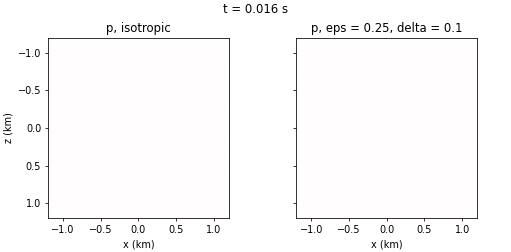

In [5]:
c = (n - 1) * h / 2e3
ext = [-c, c, c, -c]
gif = save_gif("71_symbolic_vti.gif", [("p, isotropic", frames["p"][:, 0]),
                           ("p, eps = 0.25, delta = 0.1", frames["p"][:, 1])], t, ext)
Image(filename=gif)